1.
<p>Load seaborn's `mpg` dataset in a notebook named 'mpg_seaborn.ipynb', drop rows with missing values and print the shape. Build `sns.pairplot` for mpg, horsepower, weight and acceleration with `hue='origin'` and `corner=True`, saved as 'mpg_pairplot.png'. Hint: `pairplot` returns a `PairGrid`, so save it with `g.savefig('mpg_pairplot.png')`.</p>
2.
<p>Compute the correlation matrix of the numeric columns with `corr(numeric_only=True)` and draw `sns.heatmap` with `annot=True`, `fmt='.2f'`, `cmap='coolwarm'`, `vmin=-1` and `vmax=1`, hiding the upper triangle with an `np.triu` mask. Save it as 'mpg_corr.png' and print the column most negatively correlated with mpg.</p>
3.
<p>Build three figure-level charts: `sns.relplot(kind='line')` of mpg by model_year with `hue='origin'`, `sns.catplot(kind='bar')` of mean mpg by cylinders with `errorbar=('ci', 95)`, and `sns.displot` of mpg with `hue='origin'` and `kde=True`. Save them with `g.savefig` as 'mpg_relplot.png', 'mpg_catplot.png' and 'mpg_displot.png'.</p>
4.
<p>Draw a `sns.jointplot` of weight against mpg with `kind='reg'`, showing the scatter, regression line and marginal histograms, saved as 'mpg_joint.png'. Print the files matching `Path('.').glob('mpg_*.png')`, which must be six. Run Restart & Run All and push to 's13_mpg_seaborn' in your GitHub repo 'ds_analysis_portfolio'.</p>


In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

# Load MPG dataset
df = sns.load_dataset('mpg')

# Remove missing values
df = df.dropna()

# Display data
print(df.head())

# Print shape
print("Dataset Shape:", df.shape)

print("Total Rows:", len(df))

    mpg  cylinders  displacement  horsepower  weight  acceleration  \
0  18.0          8         307.0       130.0    3504          12.0   
1  15.0          8         350.0       165.0    3693          11.5   
2  18.0          8         318.0       150.0    3436          11.0   
3  16.0          8         304.0       150.0    3433          12.0   
4  17.0          8         302.0       140.0    3449          10.5   

   model_year origin                       name  
0          70    usa  chevrolet chevelle malibu  
1          70    usa          buick skylark 320  
2          70    usa         plymouth satellite  
3          70    usa              amc rebel sst  
4          70    usa                ford torino  
Dataset Shape: (392, 9)
Total Rows: 392


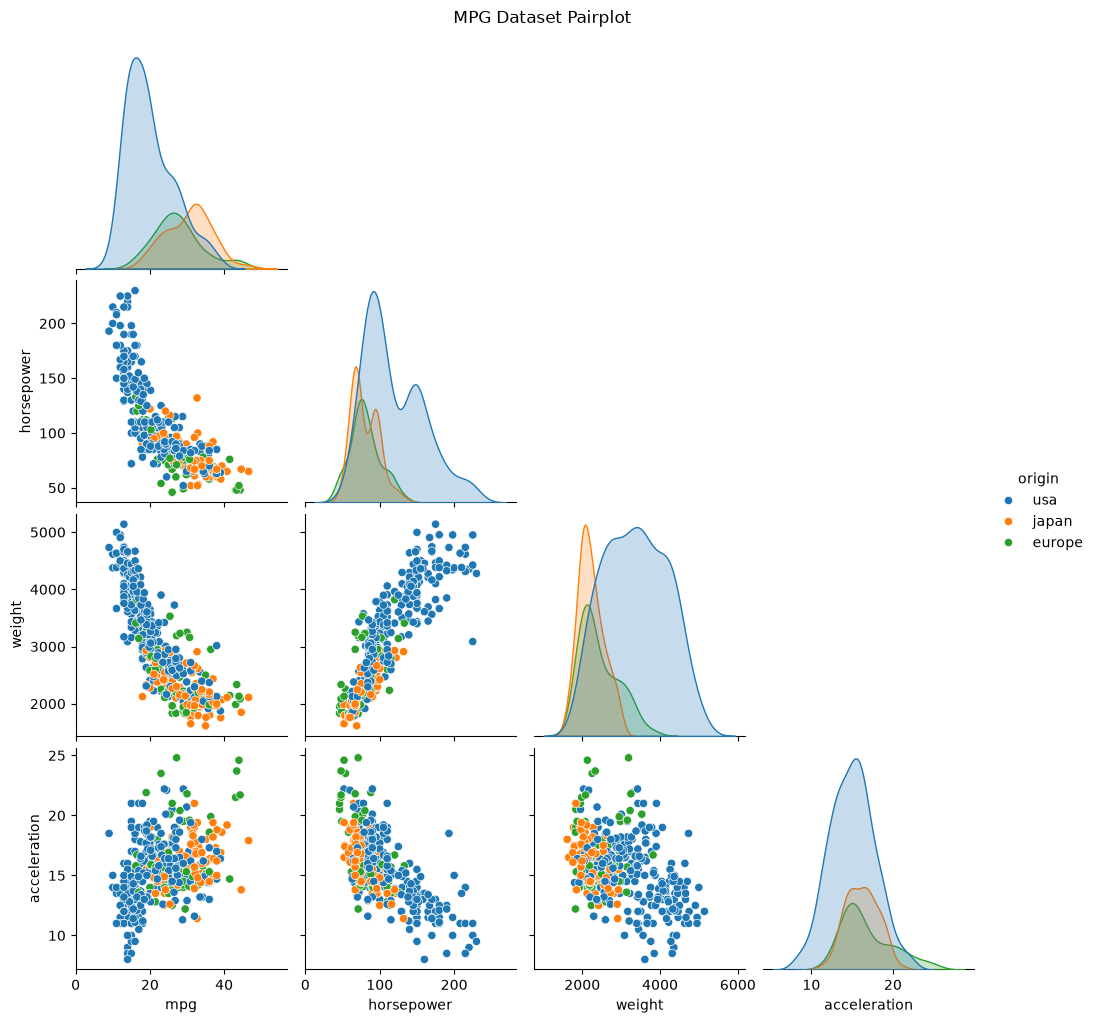

In [2]:
# Select required columns
pair_data = df[
    ['mpg', 'horsepower', 'weight', 'acceleration', 'origin']
]

# Create pairplot
g = sns.pairplot(
    pair_data,
    hue='origin',
    corner=True
)

g.fig.suptitle("MPG Dataset Pairplot", y=1.02)

# Save image
g.savefig('mpg_pairplot.png')

plt.show()

                   mpg  cylinders  displacement  horsepower    weight  \
mpg           1.000000  -0.777618     -0.805127   -0.778427 -0.832244   
cylinders    -0.777618   1.000000      0.950823    0.842983  0.897527   
displacement -0.805127   0.950823      1.000000    0.897257  0.932994   
horsepower   -0.778427   0.842983      0.897257    1.000000  0.864538   
weight       -0.832244   0.897527      0.932994    0.864538  1.000000   
acceleration  0.423329  -0.504683     -0.543800   -0.689196 -0.416839   
model_year    0.580541  -0.345647     -0.369855   -0.416361 -0.309120   

              acceleration  model_year  
mpg               0.423329    0.580541  
cylinders        -0.504683   -0.345647  
displacement     -0.543800   -0.369855  
horsepower       -0.689196   -0.416361  
weight           -0.416839   -0.309120  
acceleration      1.000000    0.290316  
model_year        0.290316    1.000000  


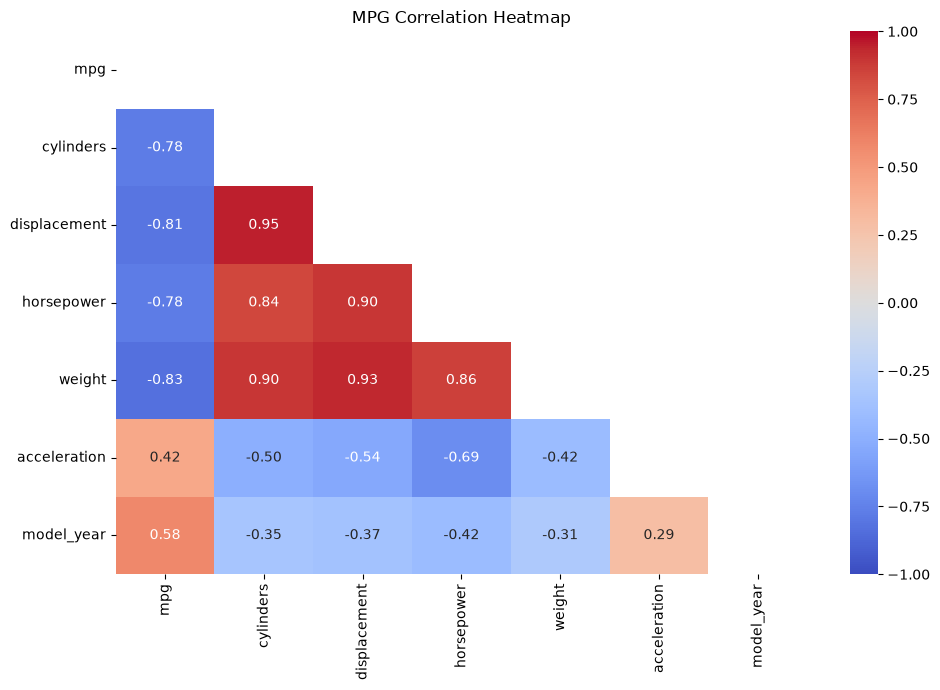

Most negatively correlated with MPG: weight
Correlation value: -0.832244214831575


In [3]:
# Calculate correlation matrix
corr = df.corr(numeric_only=True)

print(corr)

# Create upper triangle mask
mask = np.triu(np.ones_like(corr, dtype=bool))

# Draw heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    mask=mask
)

plt.title("MPG Correlation Heatmap")

plt.tight_layout()

plt.savefig('mpg_corr.png')

plt.show()

# Find most negatively correlated column with mpg
negative_corr = corr['mpg'].drop('mpg')

most_negative = negative_corr.idxmin()

print("Most negatively correlated with MPG:", most_negative)
print("Correlation value:", negative_corr.min())

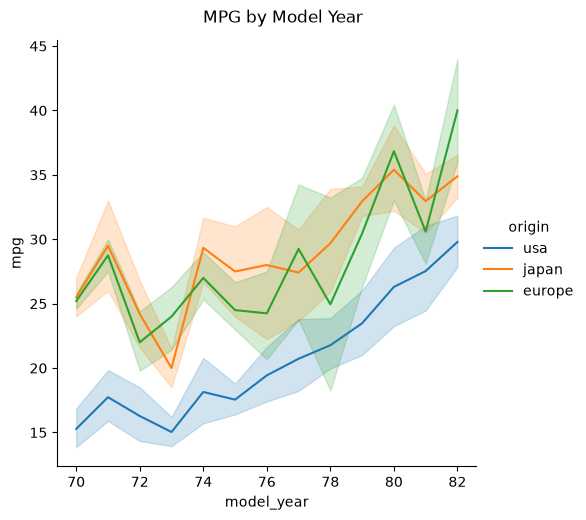

In [4]:
# Line chart
g = sns.relplot(
    data=df,
    x='model_year',
    y='mpg',
    hue='origin',
    kind='line'
)

g.fig.suptitle("MPG by Model Year", y=1.03)

g.savefig('mpg_relplot.png')

plt.show()

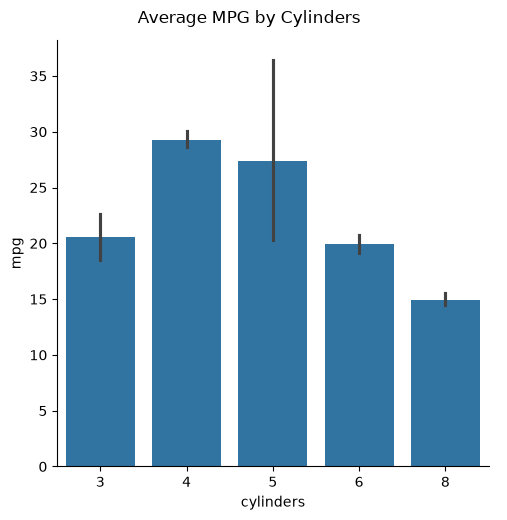

In [5]:
# Bar chart
g = sns.catplot(
    data=df,
    x='cylinders',
    y='mpg',
    kind='bar',
    errorbar=('ci', 95)
)

g.fig.suptitle("Average MPG by Cylinders", y=1.03)

g.savefig('mpg_catplot.png')

plt.show()

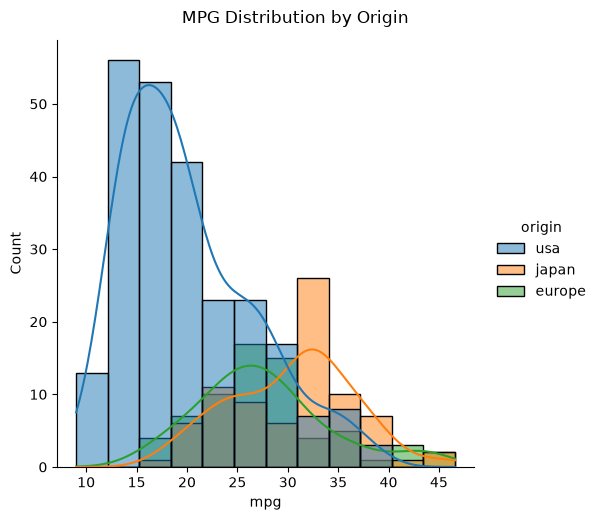

In [6]:
# Distribution plot
g = sns.displot(
    data=df,
    x='mpg',
    hue='origin',
    kde=True
)

g.fig.suptitle("MPG Distribution by Origin", y=1.03)

g.savefig('mpg_displot.png')

plt.show()

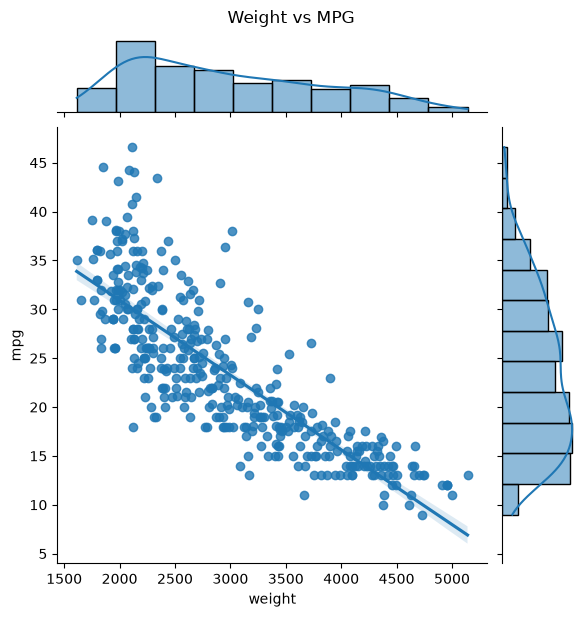

In [7]:
# Joint plot
g = sns.jointplot(
    data=df,
    x='weight',
    y='mpg',
    kind='reg'
)

g.fig.suptitle("Weight vs MPG", y=1.02)

g.savefig('mpg_joint.png')

plt.show()

In [8]:
# Find all MPG PNG files
files = list(Path('.').glob('mpg_*.png'))

print("Generated PNG Files:")

for file in files:
    print(file.name)

print("Total PNG Files:", len(files))

# Check all six files
assert len(files) == 6

print("All six images created successfully!")

Generated PNG Files:
mpg_catplot.png
mpg_corr.png
mpg_displot.png
mpg_joint.png
mpg_pairplot.png
mpg_relplot.png
Total PNG Files: 6
All six images created successfully!
